# Sensor Data for Generative and Foundation Models

> **Who is this for:** engineers who can train a basic classifier and now want to know how sensor data (IMU, LiDAR, radar, camera) is turned into **better training data** and **bigger models**: data engines, augmentation, simulation, synthetic data, generative models and foundation models.
>
> **What you will learn:**
> - the **data engine** loop (collect, label, train, deploy, mine hard cases, repeat), **auto-labeling** with a bigger offline model, and why **hard-case mining** finds what auto-labeling cannot
> - **data augmentation** for time series (jitter, scaling, rotation, time-warp, window slicing, mixup) and for point clouds (rotation, scaling, point dropout, **copy-paste** of objects), with experiments that show when it helps and when it hurts
> - **simulation and synthetic data**: sensor simulators, **domain randomization**, the **sim2real gap** and how to **measure** it
> - a small **generative model** (PCA + Gaussian mixture) that creates synthetic IMU windows, checked with **TSTR** (train on synthetic, test on real), a **discriminator test** and a memorization check; how **GANs and diffusion** models do this at scale
> - **foundation models** for sensors: time-series models, wearable and IMU models, LiDAR pretraining, **world models** for driving
> - **self-supervised contrastive learning** on unlabeled sensor streams (a numpy toy you can run)
> - **multimodal sensor-language models**, **privacy and data governance** for sensor data, and **digital twins**
>
> **Prerequisites:** [02_imu_activity_recognition_and_fall_detection.ipynb](02_imu_activity_recognition_and_fall_detection.ipynb) (IMU windows and features), [04_lidar_point_clouds_from_zero.ipynb](04_lidar_point_clouds_from_zero.ipynb) (point clouds). Helpful: [Active learning](../03_Machine_Learning/13_active_learning/01_active_learning.ipynb), [Self-supervised learning](../05_Deep_Learning/09_self_supervised_learning.ipynb), [Synthetic tabular data](../03_Machine_Learning/15_synthetic_tabular_data/01_synthetic_tabular_data.ipynb), [Synthetic data for LLMs](../08_LLM/10_synthetic_data/01_synthetic_data.ipynb).
>
> **Time needed:** about 2-3 hours. The notebook runs in about a minute.
>
> **Runs on:** CPU, no API key, no internet. numpy, scipy, pandas, scikit-learn and matplotlib only. Where a real system would call a large model, we use a small stand-in and say so.

## 0. Setup and a small IMU simulator

We need lots of sensor data with known labels, so we simulate a wrist or pocket **accelerometer** (3 axes, in units of g, 50 samples per second, windows of 128 samples = 2.56 s). Four activities:

| Class | What the signal looks like |
|---|---|
| `still` | only gravity (about 1 g on the vertical axis) plus tiny noise |
| `walk` | about 1.9 steps per second, moderate bounce |
| `run` | about 2.7 steps per second, strong bounce |
| `stairs` | slower steps (about 1.5 per second) plus an extra slow lift every second step |

"Real-world" effects we can switch on: random **device orientation** (the phone sits in the pocket at any angle), different **people** (amplitude and step rate vary), sensor **noise** and **bias**, and **clipping** at +-2 g (the sensor's range). The simulator is a teaching stand-in; [notebook 02](02_imu_activity_recognition_and_fall_detection.ipynb) covers IMU signals properly.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

SEED = 0
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 90
T_START = time.time()

FS, N_T = 50, 128                       # sample rate (Hz) and window length (samples)
CLASSES = ["still", "walk", "run", "stairs"]
t_axis = np.arange(N_T) / FS

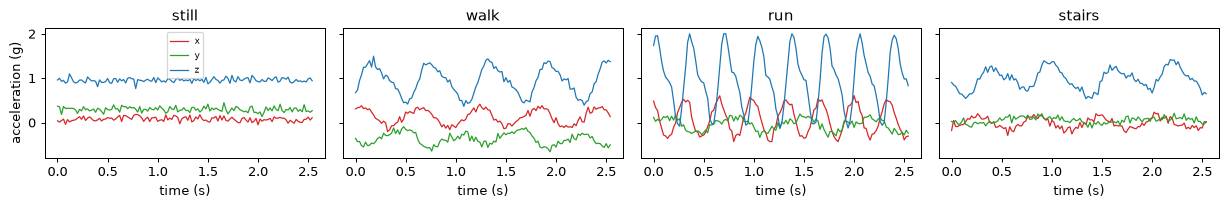

In [2]:
def random_rotation(rng, max_deg=180):
    """A random 3-D rotation of up to max_deg degrees (Rodrigues' formula)."""
    axis = rng.normal(size=3); axis /= np.linalg.norm(axis)
    ang = np.deg2rad(rng.uniform(0, max_deg))
    K = np.array([[0, -axis[2], axis[1]], [axis[2], 0, -axis[0]], [-axis[1], axis[0], 0]])
    return np.eye(3) + np.sin(ang) * K + (1 - np.cos(ang)) * K @ K

def make_imu(n, rng, domain="real", amp_range=(0.8, 1.25), freq_jit=(0.9, 1.1), max_rot=40, class_p=None):
    """Simulate n accelerometer windows, shape (n, 3, N_T), plus labels.
    domain="sim": perfect sensor, upright phone. domain="real": rotation, noise, bias, clipping."""
    y = rng.choice(4, n, p=class_p)
    X = np.zeros((n, 3, N_T))
    for i in range(n):
        s, fj, ph = rng.uniform(*amp_range), rng.uniform(*freq_jit), rng.uniform(0, 2 * np.pi)
        sig = np.zeros((3, N_T))
        if y[i] == 0:                                            # still
            sig[0] = 0.02 * np.sin(2 * np.pi * 0.3 * t_axis + ph)
        else:
            f = {1: 1.9, 2: 2.7, 3: 1.5}[y[i]] * fj              # step frequency (Hz)
            A = {1: 0.3, 2: 1.0, 3: 0.35}[y[i]] * s              # bounce amplitude (g)
            h2 = 0.4 if y[i] == 2 else 0.3
            sig[2] = A * np.sin(2 * np.pi * f * t_axis + ph) + h2 * A * np.sin(4 * np.pi * f * t_axis + 2 * ph)
            sig[0] = 0.5 * A * np.sin(2 * np.pi * f * t_axis + ph + np.pi / 2)
            sig[1] = 0.2 * A * np.sin(np.pi * f * t_axis + ph)
            if y[i] == 3:                                        # stairs: slow lift every second step
                sig[2] += 0.15 * s * np.sin(np.pi * f * t_axis + ph)
        sig[2] += 1.0                                            # gravity
        if domain == "real":
            sig = random_rotation(rng, max_rot) @ sig           # phone orientation
            sig += rng.normal(0, 0.05, sig.shape) + rng.normal(0, 0.03, (3, 1))   # noise + bias
            sig = np.clip(sig, -2.0, 2.0)                        # sensor range
        X[i] = sig
    return X, y

def features(X):
    """Hand-made window features (same idea as notebook 02): per-axis mean/std,
    magnitude statistics and the magnitude spectrum."""
    mag = np.linalg.norm(X, axis=1)
    spec = np.abs(np.fft.rfft(mag - mag.mean(axis=1, keepdims=True), axis=1))[:, 1:20]
    return np.column_stack([X.mean(axis=2), X.std(axis=2), mag.mean(1), mag.std(1),
                            np.percentile(mag, 10, axis=1), np.percentile(mag, 90, axis=1), spec])

def rf(n=150):
    return RandomForestClassifier(n_estimators=n, random_state=SEED, n_jobs=-1)

REAL = dict(amp_range=(0.6, 1.5), freq_jit=(0.85, 1.15), max_rot=60)    # "real world" settings
fig, axes = plt.subplots(1, 4, figsize=(14, 2.4), sharey=True)
for c_ in range(4):
    onehot = np.eye(4)[c_]                                       # force this class
    x = make_imu(1, np.random.default_rng(c_), class_p=onehot, **REAL)[0][0]
    for a, col in zip(range(3), ["tab:red", "tab:green", "tab:blue"]):
        axes[c_].plot(t_axis, x[a], c=col, lw=1, label="xyz"[a])
    axes[c_].set_title(CLASSES[c_]); axes[c_].set_xlabel("time (s)")
axes[0].set_ylabel("acceleration (g)"); axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 1. The data engine: how sensor data feeds the next model

**What it is.** A **data engine** is the loop that turns a deployed model's experience into better training data for the next model. In sensor-heavy products (cars, robots, wearables, phones) it is often more important than the model architecture.

**Simple analogy.** A driving school that records every lesson, finds the moments where students made mistakes, explains those moments in detail, and uses them in the next class.

```mermaid
flowchart LR
    A[Collect<br/>fleet / devices / test drives] --> B[Label<br/>humans + auto-labeling]
    B --> C[Train<br/>model version N+1]
    C --> D[Evaluate<br/>held-out + scenario tests]
    D --> E[Deploy<br/>often in shadow mode first]
    E --> F[Mine hard cases<br/>errors, low confidence, rare events,<br/>disagreement with other sensors]
    F --> A
```

| Step | What happens with sensor data | Typical tools and tricks |
|---|---|---|
| **Collect** | log raw streams with exact timestamps and calibration | triggers ("save the 10 s around a hard brake"), on-device filtering to save bandwidth |
| **Label** | boxes on LiDAR, activity labels on IMU, tracks over time | annotation tools, **auto-labeling** with bigger offline models, human review |
| **Train** | models for detection, tracking, activity, prediction | augmentation (section 2), synthetic data (sections 3-4), pretraining (section 5) |
| **Evaluate** | scenario-based tests (night, rain, rare objects), not only one average number | slice metrics, regression tests |
| **Deploy** | ship to devices; run in **shadow mode** (predict but do not act) to compare | A/B tests, monitoring |
| **Mine** | find the cases the model gets wrong or is unsure about | uncertainty, disagreement between models or sensors, **active learning** |

### 1.1 Labeling: humans, auto-labeling and hard-case mining

- **Human labeling** is accurate but slow and expensive, especially for 3D boxes and long time series.
- **Auto-labeling** uses a **bigger, slower "teacher" model offline**. Offline, there is no real-time limit, so the teacher can use bigger networks, **ensembles** (several models voting), **test-time augmentation** (averaging predictions over several transformed copies), and even **future frames** (knowing where an object went helps label where it was). Its confident predictions become labels for a smaller real-time "student" model. This is also called **pseudo-labeling** or self-training.
- **Hard-case mining / active learning** sends the examples the current model is most **unsure** about to humans, because those labels teach the most. Details: [01_active_learning.ipynb](../03_Machine_Learning/13_active_learning/01_active_learning.ipynb).

**Demo.** A pool of 1,500 unlabeled windows where `stairs` is **rare** (3%), like real fleets where interesting events are rare (the **long tail**). We start with 16 randomly chosen human labels, then compare: auto-labeling the pool with a teacher, labeling 40 more random windows, or labeling the 40 windows the model is least sure about. We report **balanced accuracy** (the average of per-class accuracies) so the rare class counts as much as the others.

In [3]:
def augment_views(X, rng, n_views):
    """Rotated, rescaled, noisy copies of each window (used by the teacher)."""
    return [np.stack([random_rotation(rng, 60) @ (x * rng.uniform(0.7, 1.4)) + rng.normal(0, 0.03, x.shape) for x in X])
            for _ in range(n_views)]

rows = []
t0 = time.time()
for run in range(3):
    r = np.random.default_rng(10 + run)
    Xpool, ypool = make_imu(1500, r, class_p=[0.4, 0.4, 0.17, 0.03], **REAL)   # stairs are rare
    Xte, yte = make_imu(1000, r, **REAL)                                        # balanced test set
    Fp, Ft = features(Xpool), features(Xte)
    seed = r.choice(len(ypool), 16, replace=False)                             # 16 random human labels
    rest = np.setdiff1d(np.arange(len(ypool)), seed)

    def train_student(idx, labels):
        m = rf(100).fit(Fp[idx], labels)
        return m, balanced_accuracy_score(yte, m.predict(Ft))

    m0, acc_seed = train_student(seed, ypool[seed])

    # (a) auto-labeling: a bigger teacher, trained on augmented seed data, predicts with test-time augmentation
    Xa = np.concatenate([Xpool[seed]] + augment_views(Xpool[seed], r, 30))
    teacher = rf(400).fit(features(Xa), np.tile(ypool[seed], 31))
    proba = np.mean([teacher.predict_proba(features(v)) for v in augment_views(Xpool[rest], r, 5)], axis=0)
    confident = proba.max(axis=1) > 0.7
    auto_y = teacher.classes_[proba.argmax(axis=1)]
    _, acc_auto = train_student(np.r_[seed, rest[confident]], np.r_[ypool[seed], auto_y[confident]])

    # (b) 40 more human labels, chosen at random
    rnd = r.choice(rest, 40, replace=False)
    _, acc_rnd = train_student(np.r_[seed, rnd], ypool[np.r_[seed, rnd]])
    # (c) 40 more human labels, chosen where the seed model is least confident (hard-case mining)
    hard = rest[np.argsort(m0.predict_proba(Fp[rest]).max(axis=1))[:40]]
    _, acc_hard = train_student(np.r_[seed, hard], ypool[np.r_[seed, hard]])

    rows.append({"run": run, "stairs in seed": int(np.sum(ypool[seed] == 3)),
                 "auto-labels used": int(confident.sum()), "auto-label accuracy": (auto_y[confident] == ypool[rest][confident]).mean(),
                 "seed only": acc_seed, "+ auto-labels": acc_auto, "+ 40 random labels": acc_rnd, "+ 40 hardest labels": acc_hard,
                 "stairs among random 40": int(np.sum(ypool[rnd] == 3)), "stairs among hardest 40": int(np.sum(ypool[hard] == 3))})
res = pd.DataFrame(rows)
print(res.round(3).to_string(index=False))
print("\nmean balanced accuracy:")
print(res[["seed only", "+ auto-labels", "+ 40 random labels", "+ 40 hardest labels"]].mean().round(3).to_string())
print(f"({time.time()-t0:.1f} s)")

 run  stairs in seed  auto-labels used  auto-label accuracy  seed only  + auto-labels  + 40 random labels  + 40 hardest labels  stairs among random 40  stairs among hardest 40
   0               0              1382                0.972      0.718          0.750               0.753                0.800                       3                        3
   1               2              1277                0.937      0.590          0.680               0.851                0.979                       2                       13
   2               3              1219                1.000      0.813          0.944               0.860                0.892                       2                        3

mean balanced accuracy:
seed only              0.707
+ auto-labels          0.791
+ 40 random labels     0.821
+ 40 hardest labels    0.890
(6.2 s)


What this toy shows (the exact numbers vary from run to run, which is itself a lesson about small label budgets):

- **Auto-labeling** produces many labels for free, they are mostly correct, and it often helps. But it only **scales what the teacher already knows**. When the seed set contains no `stairs` example at all, the teacher can never output that class, so the student cannot learn it from auto-labels.
- **Random extra labels** include only a few examples of the rare class, because it is rare.
- **Hard-case mining** picks the windows where the model is confused, and the confusing ones are often exactly the rare `stairs` windows. Usually this gives the biggest gain per human label.

Real data engines use **both**: auto-labeling for the bulk, humans for the hard and rare cases, and they keep checking auto-label quality on a human-reviewed sample.

## 2. Data augmentation for sensor data

**What it is.** **Data augmentation** creates new training examples by transforming existing ones in ways that **do not change the label**. It teaches the model which variations do not matter.

**Simple analogy.** Showing a child the same dog photographed from different angles and in different light, so they learn "dog", not "this exact photo".

**The golden rule:** an augmentation must be **label-preserving**. Rotating a phone's signal is fine (the person still walks). Speeding up a walking signal too much can turn it into running, or slowing it down can turn it into stairs, which **creates wrong labels**.

### 2.1 Time-series augmentations

| Augmentation | What it does | Models the real-world effect | Watch out |
|---|---|---|---|
| **Jitter** | add small random noise | sensor noise | too much noise hides the signal |
| **Scaling** | multiply each axis by a random factor | different people, sensor gain | |
| **Rotation** | rotate the 3 axes together | phone held or worn at a different angle | not for sensors with a fixed mount |
| **Time-warp** | stretch or squeeze time a little | slightly faster or slower movement | changes frequency, which can change the class |
| **Window slicing** | take a random 80% crop and stretch it back to full length | different start of the window | also changes frequency a little |
| **Mixup** | blend two windows: $\lambda x_i + (1-\lambda) x_j$, with a soft label | smoother decision boundaries | blended signals are not physically real |

Mixup needs a **soft label** ($\lambda$ of class $i$, $1-\lambda$ of class $j$). Random forests take only hard labels, so we use a standard trick: add the mixed window **twice**, once with label $i$ and weight $\lambda$, once with label $j$ and weight $1-\lambda$.

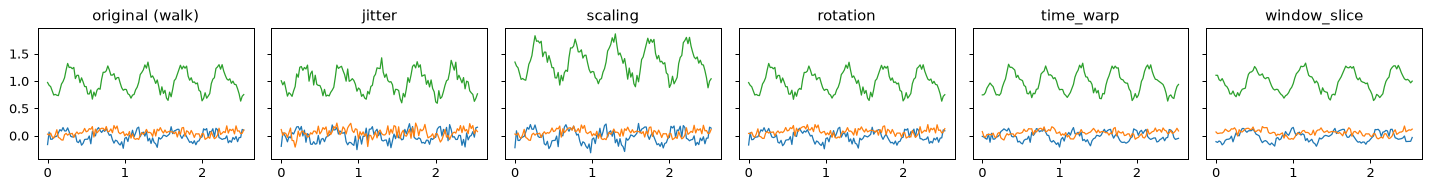

In [4]:
def jitter(x, rng):       return x + rng.normal(0, 0.05, x.shape)
def scaling(x, rng):      return x * rng.uniform(0.7, 1.4, (3, 1))
def rotation(x, rng):     return random_rotation(rng, 45) @ x
def time_warp(x, rng):
    k = rng.uniform(0.9, 1.1)                                    # speed factor
    src = (N_T - 1) / 2 + (np.arange(N_T) - (N_T - 1) / 2) * k   # stretch around the window centre
    xp = np.pad(x, ((0, 0), (N_T, N_T)), mode="reflect")         # padding so we never run out of signal
    return np.stack([np.interp(src + N_T, np.arange(xp.shape[1]), a) for a in xp])
def window_slice(x, rng):
    L = int(N_T * 0.8); s = rng.integers(0, N_T - L + 1)
    return np.stack([np.interp(np.linspace(0, L - 1, N_T), np.arange(L), a[s:s + L]) for a in x])

AUGS = dict(jitter=jitter, scaling=scaling, rotation=rotation, time_warp=time_warp, window_slice=window_slice)

x0 = make_imu(1, np.random.default_rng(3), class_p=[0, 1, 0, 0], **REAL)[0][0]
fig, axes = plt.subplots(1, 6, figsize=(16, 2.2), sharey=True)
axes[0].plot(t_axis, x0.T, lw=1); axes[0].set_title("original (walk)")
for ax, (name, fn) in zip(axes[1:], AUGS.items()):
    ax.plot(t_axis, fn(x0, np.random.default_rng(4)).T, lw=1); ax.set_title(name)
plt.tight_layout(); plt.show()

**Experiment.** Train with only **24 labeled windows** recorded in a narrow setting (similar people, phone held almost upright). Test on 1,500 windows from the "real world" (many people, any orientation, varied step rates). Compare no augmentation, each augmentation alone, mixup, and all together (10 augmented copies per window). Averaged over 3 random training sets.

In [5]:
def augment_set(X, y, fns, n_copies, rng, mixup=False):
    """Return augmented X, y and sample weights. Each copy applies one randomly chosen function."""
    Xs, ys, ws = [X], [y], [np.ones(len(y))]
    if fns:
        for _ in range(n_copies):
            Xs.append(np.stack([fns[rng.integers(len(fns))](x, rng) for x in X])); ys.append(y); ws.append(np.ones(len(y)))
    if mixup:
        for _ in range(n_copies):
            j = rng.permutation(len(y)); lam = rng.beta(0.4, 0.4, len(y))
            Xm = lam[:, None, None] * X + (1 - lam[:, None, None]) * X[j]
            Xs += [Xm, Xm]; ys += [y, y[j]]; ws += [lam, 1 - lam]   # soft label as two weighted rows
    return np.concatenate(Xs), np.concatenate(ys), np.concatenate(ws)

t0 = time.time()
Xte_aug, yte_aug = make_imu(1500, np.random.default_rng(99), amp_range=(0.6, 1.5), freq_jit=(0.8, 1.2), max_rot=40)
Fte_aug = features(Xte_aug)
configs = [("none", [], False)] + [(k, [v], False) for k, v in AUGS.items()] + [("mixup", [], True), ("all of the above", list(AUGS.values()), True)]
scores = {name: [] for name, _, _ in configs}
for run in range(3):
    r = np.random.default_rng(100 + run)
    Xtr, ytr = make_imu(24, r, amp_range=(0.95, 1.05), freq_jit=(0.97, 1.03), max_rot=10)   # narrow training data
    for name, fns, mix in configs:
        Xa, ya, wa = augment_set(Xtr, ytr, fns, 10, r, mixup=mix)
        clf = rf().fit(features(Xa), ya, sample_weight=wa)
        scores[name].append((clf.predict(Fte_aug) == yte_aug).mean())
aug_table = pd.DataFrame({"mean test accuracy": {k: np.mean(v) for k, v in scores.items()},
                          "std over 3 runs": {k: np.std(v) for k, v in scores.items()}}).round(3)
print(aug_table.to_string())
print(f"({time.time()-t0:.1f} s)")

                  mean test accuracy  std over 3 runs
none                           0.877            0.006
jitter                         0.862            0.013
scaling                        0.893            0.026
rotation                       0.880            0.021
time_warp                      0.819            0.004
window_slice                   0.818            0.006
mixup                          0.893            0.014
all of the above               0.955            0.010
(6.5 s)


How to read the result:

- **Combining** augmentations gives the clearest gain: the test data differs from the training data in several ways at once (orientation, amplitude, step rate), so the model needs to see all of those variations.
- **Single** augmentations give small changes, and some **hurt** on their own. Time-warp and window slicing change the step frequency, and step frequency is exactly what separates `walk` from `stairs` here. This is the label-preserving rule in action: always check each augmentation on a validation set instead of assuming it helps.
- Augmentation is cheap "domain knowledge in code". It works best when you know **how** your deployment data differs from your training data.

### 2.2 Point-cloud augmentations

| Augmentation | What it does | Why |
|---|---|---|
| **Global rotation** (around the vertical axis) | spin the whole scene or object | objects appear at every heading |
| **Global scaling** | multiply coordinates by 0.95-1.05 | size variation between object instances |
| **Point dropout** | randomly delete points | far or partly hidden objects have fewer points |
| **Jitter** | small noise per point | range noise |
| **Flip** | mirror left-right | roads exist in both directions (careful with text and traffic rules) |
| **Copy-paste (GT sampling)** | cut labeled objects from other scans and paste them into this scene | more examples of rare classes; introduced in the SECOND detector (2018) |

**Experiment.** Classify 3 object types (car, cyclist, pedestrian) from simple shape features of their points. The training data only contains objects with **heading 0** and **close range** (many points). The test data has **any heading** and **any range** (from very sparse to dense). Features: extent in x, y, z, number of points, spread per axis.

In [6]:
OBJ = ["car", "cyclist", "pedestrian"]
def sample_object(cls, rng, density, yaw):
    """Points on the surface of a box-shaped object. density = points per square metre of surface."""
    if cls == 0:   L, W, H = rng.uniform(4.0, 4.8), rng.uniform(1.7, 1.9), rng.uniform(1.4, 1.6)
    elif cls == 1: L, W, H = rng.uniform(1.6, 1.9), rng.uniform(0.5, 0.7), rng.uniform(1.6, 1.8)
    else:          L = W = 2 * rng.uniform(0.25, 0.35); H = rng.uniform(1.6, 1.9)
    n = max(8, int(2 * (L * W + L * H + W * H) * density * rng.uniform(0.7, 1.3)))
    p = rng.uniform(-0.5, 0.5, (n, 3)) * [L, W, H]
    f = rng.integers(0, 3, n)
    p[np.arange(n), f] = np.sign(p[np.arange(n), f]) * np.array([L, W, H])[f] / 2   # push onto a face
    p[:, 2] += H / 2
    c_, s_ = np.cos(yaw), np.sin(yaw)
    p[:, :2] = p[:, :2] @ np.array([[c_, -s_], [s_, c_]]).T
    return p + rng.normal(0, 0.02, p.shape)

def pc_features(p):
    return [np.ptp(p[:, 0]), np.ptp(p[:, 1]), np.ptp(p[:, 2]), len(p), p[:, 0].std(), p[:, 1].std(), p[:, 2].std()]

def pc_rotate(p, rng):
    a = rng.uniform(-np.pi, np.pi); c_, s_ = np.cos(a), np.sin(a)
    q = p.copy(); q[:, :2] = q[:, :2] @ np.array([[c_, -s_], [s_, c_]]).T
    return q
def pc_dropout(p, rng):
    keep = rng.random(len(p)) < rng.uniform(0.1, 1.0); keep[:3] = True     # keep at least 3 points
    return p[keep]
def pc_scale(p, rng):  return p * rng.uniform(0.95, 1.05)
def pc_jitter(p, rng): return p + rng.normal(0, 0.03, p.shape)

r = np.random.default_rng(4)
y_tr = np.repeat(np.arange(3), 40)
train_objs = [sample_object(k, r, density=60, yaw=0.0) for k in y_tr]                       # heading 0, dense
y_te = r.integers(0, 3, 1500)
test_objs = [sample_object(k, r, density=r.uniform(5, 60), yaw=r.uniform(-np.pi, np.pi)) for k in y_te]
F_te = np.array([pc_features(p) for p in test_objs])

rows = []
for name, fns in [("none", []), ("jitter + scaling", [pc_jitter, pc_scale]), ("rotation", [pc_rotate]),
                  ("point dropout", [pc_dropout]), ("all four", [pc_rotate, pc_dropout, pc_scale, pc_jitter])]:
    objs, labels = list(train_objs), list(y_tr)
    for _ in range(10 if fns else 0):
        for p, k in zip(train_objs, y_tr):
            for fn in fns:
                p = fn(p, r)                       # apply every function in the list
            objs.append(p); labels.append(k)
    clf = rf().fit(np.array([pc_features(p) for p in objs]), labels)
    rows.append({"augmentation": name, "test accuracy": (clf.predict(F_te) == y_te).mean()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

    augmentation  test accuracy
            none          0.824
jitter + scaling          0.800
        rotation          0.819
   point dropout          0.805
        all four          1.000


The test set differs from training in **two** ways: heading and point density. Fixing only one of them is not enough (a rotated cyclist looks like a pedestrian in the x-extent; a sparse car has far fewer points than any training car). Only augmenting **both** closes the gap. This is the same lesson as for the IMU: list every way deployment data can differ, and cover each one.

**Copy-paste augmentation** in one picture: objects cut from other scans (a "database" of labeled objects) are pasted into free space of a scene, checking that they do not overlap existing objects. Real implementations also check that the pasted object is not floating or hidden behind a wall.

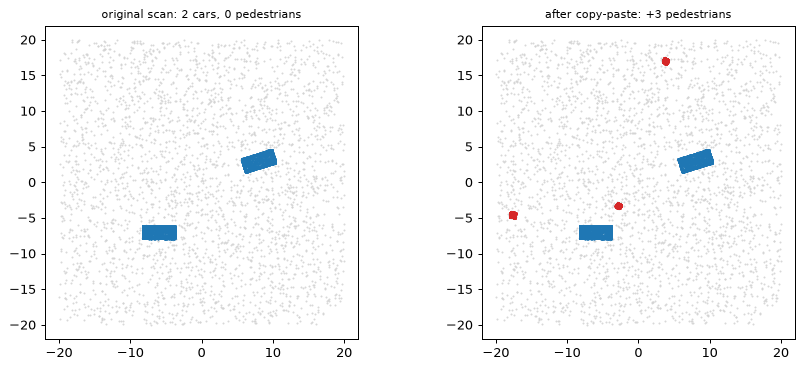

In [7]:
r = np.random.default_rng(8)
ground = np.column_stack([r.uniform(-20, 20, 3000), r.uniform(-20, 20, 3000), r.normal(0, 0.02, 3000)])
scene_objs = [sample_object(0, r, 40, 0.3) + [8, 3, 0], sample_object(0, r, 40, 0.0) + [-6, -7, 0]]
bank = [sample_object(2, r, 60, 0.0) for _ in range(5)]                     # a "database" of pedestrians

def free_spot(existing_centres, rng, min_gap=3.0):
    while True:
        xy = rng.uniform(-18, 18, 2)
        if all(np.linalg.norm(xy - c_) > min_gap for c_ in existing_centres):
            return xy

centres = [o[:, :2].mean(axis=0) for o in scene_objs]
pasted = []
for obj in bank[:3]:
    xy = free_spot(centres, r); centres.append(xy)
    pasted.append(pc_rotate(obj, r) + [xy[0], xy[1], 0])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, extra, title in [(axes[0], [], "original scan: 2 cars, 0 pedestrians"), (axes[1], pasted, "after copy-paste: +3 pedestrians")]:
    ax.scatter(ground[:, 0], ground[:, 1], s=0.3, c="lightgray")
    for o in scene_objs: ax.scatter(o[:, 0], o[:, 1], s=1, c="tab:blue")
    for o in extra: ax.scatter(o[:, 0], o[:, 1], s=2, c="tab:red")
    ax.set_aspect("equal"); ax.set_title(title, fontsize=9)
plt.tight_layout(); plt.show()

## 3. Simulation, synthetic data and the sim2real gap

**What it is.** A **sensor simulator** renders what a camera, LiDAR, radar or IMU would measure in a virtual world. You get unlimited data, perfect labels for free, and dangerous or rare situations (a child running onto the road) without risk.

**Simple analogy.** A flight simulator: pilots practise engine failures that would be too dangerous to practise in a real plane.

**Commonly used simulators** (described in general terms; check each project's current status and licence):

| Simulator | Typical use | Sensors simulated |
|---|---|---|
| **CARLA** (open source, built on Unreal Engine) | autonomous-driving research | cameras, LiDAR, radar, GNSS, IMU, semantic labels |
| **NVIDIA Isaac Sim** | robotics (arms, mobile robots, humanoids) | cameras, depth, LiDAR, IMU, contact |
| **NVIDIA DRIVE Sim** | automotive development | physically based camera, LiDAR and radar models |
| **AirSim** (Microsoft, open source; the original project has been archived) | drones and cars | cameras, depth, LiDAR, IMU, GPS |
| **Gazebo** | general robotics with ROS | many sensor plug-ins |
| Physics engines such as **MuJoCo** or **PyBullet** | robot motion and contact; IMU-like signals from simulated bodies | joint states, accelerations |

### 3.1 The sim2real gap

**What it is.** A model trained on simulated data often performs worse on real data, because the simulator is never perfect: real sensors have noise, bias, odd mounting angles, reflections, weather and wear. This difference is the **sim2real gap** (also called **domain gap** or **domain shift**).

**How to measure it.**
1. **Performance gap**: accuracy on simulated test data minus accuracy on real test data, for the same model.
2. **Domain classifier test**: train a classifier to tell sim from real. If it succeeds easily (**AUC**, area under the ROC curve, near 1.0), the domains are very different; near 0.5 means it cannot tell them apart.

### 3.2 Domain randomization

**What it is.** Instead of making the simulator perfectly realistic, make it **wildly varied**: random orientations, gains, noise levels, biases, lighting, textures. Reality then looks like "just another variation".

**Simple analogy.** If you have practised driving in sun, rain, fog and snow in the simulator, a real rainy day is not a surprise.

It is close to data augmentation (section 2), but applied **inside the simulator**, where you can vary physical parameters that cannot be changed after recording.

**Experiment.** Train on clean simulated IMU data (phone perfectly upright, no noise), test on "real" data. Then train again on domain-randomized simulated data.

In [8]:
r = np.random.default_rng(1)
X_sim, y_sim = make_imu(800, r, domain="sim")
X_sim_te, y_sim_te = make_imu(600, r, domain="sim")
X_real, y_real = make_imu(600, r, domain="real", amp_range=(0.6, 1.5), freq_jit=(0.85, 1.15), max_rot=60)

def domain_randomize(X, rng):
    """Random orientation, gain, noise level, bias and clipping for each simulated window."""
    out = []
    g = np.array([[0.0], [0.0], [1.0]])
    for x in X:
        dyn = (x - g) * rng.uniform(0.6, 1.5)                  # vary movement strength, keep gravity at 1 g
        x = random_rotation(rng, 70) @ (dyn + g)               # random phone orientation
        x = x + rng.normal(0, rng.uniform(0, 0.1), x.shape) + rng.normal(0, 0.05, (3, 1))
        out.append(np.clip(x, -2, 2))
    return np.stack(out)

def domain_auc(Fa, Fb):
    """How easily can a classifier tell domain A from domain B? 0.5 = not at all, 1.0 = perfectly."""
    F = np.vstack([Fa, Fb]); d = np.r_[np.zeros(len(Fa)), np.ones(len(Fb))]
    p = cross_val_predict(rf(100), F, d, cv=3, method="predict_proba")[:, 1]
    return roc_auc_score(d, p)

X_dr = domain_randomize(X_sim, r)
rows = []
for name, Xtrain in [("train on clean sim", X_sim), ("train on domain-randomized sim", X_dr)]:
    clf = rf().fit(features(Xtrain), y_sim)
    acc_sim = (clf.predict(features(X_sim_te)) == y_sim_te).mean()
    acc_real = (clf.predict(features(X_real)) == y_real).mean()
    rows.append({"training data": name, "accuracy on sim test": acc_sim, "accuracy on real test": acc_real,
                 "sim2real gap": acc_sim - acc_real, "domain AUC (train data vs real)": domain_auc(features(Xtrain[:600]), features(X_real))})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                 training data  accuracy on sim test  accuracy on real test  sim2real gap  domain AUC (train data vs real)
            train on clean sim                 0.998                  0.693         0.305                            1.000
train on domain-randomized sim                 1.000                  0.960         0.040                            0.806


Domain randomization shrinks the gap a lot, and the domain classifier finds it harder to tell the training data from real data. It is not free: randomizing too widely wastes model capacity on situations that never happen, and some effects (for example a specific person's gait, or LiDAR reflections from wet roads) are hard to simulate at all. Common complements: **fine-tuning on a small amount of real data**, **domain adaptation** methods, and **neural or learned simulators** that are trained on real recordings to look more realistic.

## 4. Generative models for sensor data

**What it is.** A **generative model** learns the distribution of real data and can then **sample** new, realistic examples: synthetic IMU windows, LiDAR scans, radar spectra, camera video.

**Why bother if we have simulators?** A simulator is hand-built from physics; a generative model is **learned from real recordings**, so it can capture effects nobody modelled (a person's gait, sensor quirks). Uses: more training data for rare classes, privacy-friendlier data sharing, test data for software, and filling gaps (**imputation**) in broken streams.

### 4.1 A small generator: PCA + Gaussian mixture

**How it works.**
1. Flatten each window (3 x 128 = 384 numbers).
2. **PCA** (principal component analysis) compresses it to a few numbers that capture most of the variation. Think of PCA as finding the main "shapes" that signals are built from.
3. Fit a **Gaussian mixture model** (GMM: a few overlapping bell curves) to those compressed numbers, separately for each class.
4. To generate: sample from the GMM, then undo the PCA to get a full window.

This is a simple **latent-variable model**, the same family of idea as a **VAE** (variational autoencoder), but with a **linear** decoder (PCA) instead of a neural network. It trains in a second.

generated 800 synthetic windows in 0.7 s


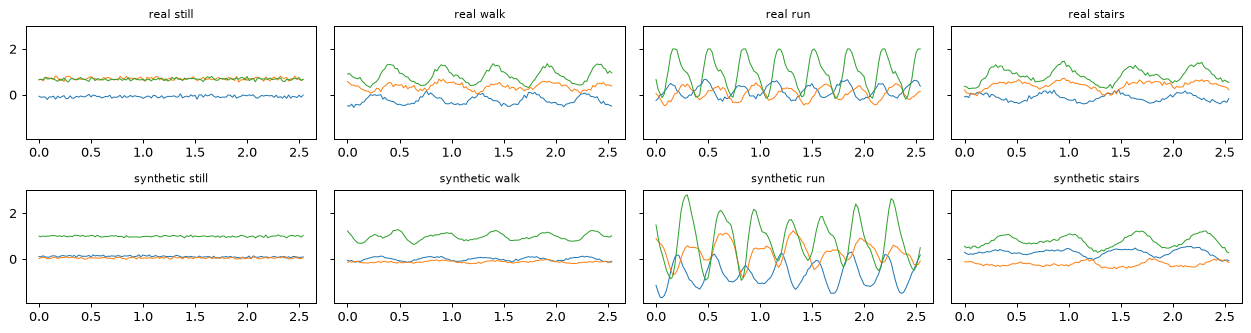

In [9]:
r = np.random.default_rng(2)
X_real_tr, y_real_tr = make_imu(800, r, **REAL)       # real training data (what we are allowed to learn from)
X_real_te, y_real_te = make_imu(800, r, **REAL)       # real held-out data (only for evaluation)

class PCAGMMGenerator:
    """Per-class generator: PCA to a small latent space, Gaussian mixture in that space."""
    def __init__(self, n_components=40, n_mix=4):
        self.n_components, self.n_mix = n_components, n_mix
    def fit(self, X, y):
        self.models = {}
        for k in np.unique(y):
            Z = X[y == k].reshape((y == k).sum(), -1)
            pca = PCA(self.n_components, random_state=SEED).fit(Z)
            gmm = GaussianMixture(self.n_mix, covariance_type="full", random_state=SEED).fit(pca.transform(Z))
            self.models[k] = (pca, gmm)
        return self
    def sample(self, n_per_class):
        Xs, ys = [], []
        for k, (pca, gmm) in self.models.items():
            z, _ = gmm.sample(n_per_class)
            Xs.append(pca.inverse_transform(z).reshape(n_per_class, 3, N_T)); ys.append(np.full(n_per_class, k))
        return np.concatenate(Xs), np.concatenate(ys)

t0 = time.time()
gen = PCAGMMGenerator().fit(X_real_tr, y_real_tr)
X_syn, y_syn = gen.sample(200)
print(f"generated {len(X_syn)} synthetic windows in {time.time()-t0:.1f} s")

fig, axes = plt.subplots(2, 4, figsize=(14, 3.8), sharey=True)
for k in range(4):
    axes[0, k].plot(t_axis, X_real_tr[y_real_tr == k][0].T, lw=0.8); axes[0, k].set_title(f"real {CLASSES[k]}", fontsize=9)
    axes[1, k].plot(t_axis, X_syn[y_syn == k][0].T, lw=0.8); axes[1, k].set_title(f"synthetic {CLASSES[k]}", fontsize=9)
plt.tight_layout(); plt.show()

### 4.2 Is the synthetic data any good? Three checks

| Check | Question | How | Good result |
|---|---|---|---|
| **TSTR** (Train on Synthetic, Test on Real) | is it **useful**? | train a classifier only on synthetic data, test on real held-out data; compare with **TRTR** (train on real, test on real) | TSTR close to TRTR |
| **Discriminator test** | is it **realistic**? | train a classifier to tell real from synthetic | AUC close to 0.5 |
| **Memorization check** | is it just **copying** training examples? | distance from each synthetic window to its closest real training window (DCR, distance to closest record), compared with real held-out windows | synthetic windows are not much closer to the training data than new real windows are |

The same three checks are used for synthetic tables in [01_synthetic_tabular_data.ipynb](../03_Machine_Learning/15_synthetic_tabular_data/01_synthetic_tabular_data.ipynb) and for synthetic text in [01_synthetic_data.ipynb](../08_LLM/10_synthetic_data/01_synthetic_data.ipynb). We also try a **naive generator** (each time step drawn independently from a bell curve with the class mean and spread) as a baseline.

In [10]:
def tstr(Xs, ys):
    return (rf().fit(features(Xs), ys).predict(features(X_real_te)) == y_real_te).mean()

# naive baseline: independent noise around the class-average window
X_naive = np.concatenate([X_real_tr[y_real_tr == k].mean(0) + r.normal(0, X_real_tr[y_real_tr == k].std(0), (200, 3, N_T)) for k in range(4)])
y_naive = np.repeat(np.arange(4), 200)

def dcr(A, B):
    """For each window in A: distance to the closest window in B (flattened, Euclidean)."""
    from scipy.spatial import cKDTree
    return cKDTree(B.reshape(len(B), -1)).query(A.reshape(len(A), -1))[0]

real_dcr = np.median(dcr(X_real_te[:400], X_real_tr))
rows = [
    {"training data": "real (TRTR, reference)", "accuracy on real test": tstr(X_real_tr, y_real_tr), "real-vs-fake AUC": np.nan, "median DCR / real DCR": 1.0},
    {"training data": "PCA+GMM synthetic (TSTR)", "accuracy on real test": tstr(X_syn, y_syn),
     "real-vs-fake AUC": domain_auc(features(X_syn), features(X_real_tr)), "median DCR / real DCR": np.median(dcr(X_syn, X_real_tr)) / real_dcr},
    {"training data": "naive noise synthetic (TSTR)", "accuracy on real test": tstr(X_naive, y_naive),
     "real-vs-fake AUC": domain_auc(features(X_naive), features(X_real_tr)), "median DCR / real DCR": np.median(dcr(X_naive, X_real_tr)) / real_dcr},
]
print(pd.DataFrame(rows).round(3).to_string(index=False))

               training data  accuracy on real test  real-vs-fake AUC  median DCR / real DCR
      real (TRTR, reference)                  1.000               NaN                  1.000
    PCA+GMM synthetic (TSTR)                  0.944             0.624                  1.095
naive noise synthetic (TSTR)                  0.689             1.000                  2.395


Reading the table: the PCA+GMM generator gives useful data (TSTR fairly close to TRTR) and is harder to tell from real data than the naive generator, but a discriminator can still spot it (AUC above 0.5). Look at the plots above for one reason: the synthetic `run` windows can go beyond +-2 g, which the real sensor can never output because it clips there. Checking **physical constraints** (sensor range, gravity close to 1 g when still, smoothness) is a cheap extra test for synthetic sensor data. Its DCR ratio is about 1: synthetic windows are about as far from the training windows as new real windows are, so it is not simply copying them. A ratio much smaller than 1 would mean **memorization**, which is a privacy risk for health or location data (section 7).

### 4.3 GANs and diffusion models for sensor data (conceptual)

| Family | Idea in one sentence | Sensor examples |
|---|---|---|
| **VAE** | encode to a small random code, decode back; sample new codes | compact generators for IMU windows, anomaly detection by reconstruction error |
| **GAN** (generative adversarial network) | a generator and a discriminator compete until fakes look real | TimeGAN (2019) for multivariate time series; RCGAN for medical time series |
| **Diffusion model** | learn to remove noise step by step; generate by denoising pure noise | time-series imputation (CSDI, 2021); LiDAR range-image generation (LiDARGen, 2022); video and occupancy generation for driving |
| **Autoregressive transformer** | predict the next token; sensor data is cut into tokens | world models for driving (section 5) |

The engineering rule is the same for all of them: **evaluate with TSTR, a discriminator and a memorization check**, and never mix synthetic data into test sets.

## 5. Sensor and time-series foundation models

**What it is.** A **foundation model** is a large model **pretrained on huge, broad data**, usually without labels, that can then be adapted to many tasks with little labeled data. For sensors, the "broad data" is years of unlabeled streams from many devices.

**Simple analogy.** A doctor who has seen a million patients learns a new rare disease from a handful of cases much faster than a student does.

This area moves fast. The table names well-known examples **as of late 2026**; treat it as a map of ideas, not a ranking, and check current releases before choosing.

| Kind | What it is pretrained on | What it can do | Examples |
|---|---|---|---|
| **Time-series forecasting FMs** | large collections of public time series (energy, traffic, weather, retail...) | **zero-shot forecasting** (predict a new series without training on it) | TimesFM (Google, 2024), Chronos (Amazon, 2024), Moirai (Salesforce, 2024), MOMENT (2024). See [advanced forecasting](../04_Forecasting/06_advanced_forecasting.ipynb) |
| **Wearable / biosignal FMs** | millions of hours of accelerometer, PPG (optical heart-rate) or ECG data | embeddings for activity, sleep and health prediction with few labels | Apple's PPG/ECG foundation models (ICLR 2024); self-supervised activity models trained on UK Biobank wrist accelerometry (2024) |
| **Motion / IMU-language models** | IMU paired with video or text | search motion with text, describe motion in words | IMU2CLIP (2022); ImageBind (2023) aligns IMU, depth, thermal, audio, image and text in one space |
| **LiDAR / 3D pretraining** | unlabeled point clouds | better 3D detectors and segmenters with fewer labels | contrastive (PointContrast, 2020) and masked-autoencoder (Point-MAE, 2022) pretraining; occupancy-prediction pretraining |
| **World models for driving and robots** | huge amounts of driving or robot video, sometimes LiDAR or occupancy | **predict how the scene will evolve** given actions; generate realistic training and test scenarios | GAIA-1 (Wayve, 2023, video), OccWorld (2023, 3D occupancy), NVIDIA Cosmos world foundation models (2025). See [frontier AI topics](../08_LLM/26_frontier_ai_topics_2026.ipynb) |

**How a world model connects to this notebook.** A world model is a **generative model of sensor data conditioned on actions**: "if the car brakes now, what will the cameras and LiDAR see in 2 seconds?" That makes it a learned simulator (section 3) that can generate rare scenarios for the data engine (section 1).

```mermaid
flowchart LR
    A[Huge unlabeled sensor logs] --> B[Self-supervised pretraining<br/>contrastive, masked, next-token]
    B --> C[Foundation model<br/>general sensor embeddings or a world model]
    C --> D1[Fine-tune: activity, fall detection]
    C --> D2[Fine-tune: 3D detection]
    C --> D3[Generate scenarios / synthetic data]
    D3 --> E[Data engine]
    E --> A
```

## 6. Self-supervised pretraining on unlabeled sensor streams

**What it is.** **Self-supervised learning (SSL)** creates a training signal from the data itself, no labels needed. **Contrastive learning** (for example SimCLR) is one recipe:
1. Take a window and make **two augmented views** of it (rotate, rescale, add noise, shift in time).
2. Train an encoder so the two views of the **same** window get **similar embeddings**, and views of **different** windows get **different** embeddings.
3. The loss that does this is **InfoNCE**: for each view, a softmax over "which of the other views in the batch is my partner?".

**Simple analogy.** Recognising your friend whether they wear a hat or not, in sun or shade: you learn what stays the same and ignore what changes.

**Why it fits sensors.** Unlabeled sensor data is nearly free (phones and cars record all day); labels are expensive. The augmentations encode what should **not** matter (phone orientation, loudness, start time), so the encoder learns to ignore it.

**Demo.** A **linear** encoder trained with InfoNCE in pure numpy (we write the gradient by hand) on 2,000 unlabeled windows. Input: the log power spectrum of each axis. Then we give it only **5 labels per class** and compare **linear probing** (logistic regression on the embedding) and a **1-nearest-neighbour** classifier on: the raw input, PCA (an unsupervised baseline of the same size), and the contrastive embedding. The full theory is in [09_self_supervised_learning.ipynb](../05_Deep_Learning/09_self_supervised_learning.ipynb).

In [11]:
r = np.random.default_rng(3)
REAL_ANY = dict(amp_range=(0.6, 1.5), freq_jit=(0.85, 1.15), max_rot=90)
X_unlab, y_hidden = make_imu(2000, r, **REAL_ANY)        # labels exist but we do NOT use them for pretraining
X_eval, y_eval = make_imu(2000, r, **REAL_ANY)

def spectrum_input(X):
    P = np.abs(np.fft.rfft(X, axis=2))[:, :, 1:33] ** 2          # power per axis, 32 frequency bins
    return np.log1p(10 * P).reshape(len(X), -1)                  # 96 numbers per window
E_unlab = spectrum_input(X_unlab)
MU, SD = E_unlab.mean(0), E_unlab.std(0) + 1e-6
def prep(X): return (spectrum_input(X) - MU) / SD

def two_views(X, rng):
    out = []
    for x in X:
        x = random_rotation(rng, 180) @ x * rng.uniform(0.8, 1.25) + rng.normal(0, 0.05, x.shape)
        out.append(np.roll(x, rng.integers(0, 16), axis=1))      # random time shift
    return np.stack(out)

def embed(Xin, W):
    z = Xin @ W
    return z / np.linalg.norm(z, axis=1, keepdims=True), z      # unit-length embedding

def info_nce_step(W, A, B, tau=0.2):
    """Symmetric InfoNCE loss and its gradient for a linear encoder W."""
    ua, za = embed(A, W); ub, zb = embed(B, W)
    logits = ua @ ub.T / tau                                      # similarity of every pair
    def softmax(L):
        e = np.exp(L - L.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
    Pab, Pba = softmax(logits), softmax(logits.T)
    n, I = len(A), np.eye(len(A))
    loss = -(np.log(np.diag(Pab)).mean() + np.log(np.diag(Pba)).mean()) / 2
    G = ((Pab - I) + (Pba - I).T) / (2 * n * tau)                 # d loss / d logits
    dua, dub = G @ ub, G.T @ ua
    def through_norm(u, z, du):                                   # gradient through z / |z|
        return (du - u * np.sum(u * du, axis=1, keepdims=True)) / np.linalg.norm(z, axis=1, keepdims=True)
    dW = A.T @ through_norm(ua, za, dua) + B.T @ through_norm(ub, zb, dub)
    return loss, dW

t0 = time.time()
D, DZ = E_unlab.shape[1], 16
W = r.normal(0, 1 / np.sqrt(D), (D, DZ))
m_, v_ = np.zeros_like(W), np.zeros_like(W)                       # Adam optimiser state
losses = []
for step in range(300):
    idx = r.choice(len(X_unlab), 128, replace=False)
    loss, dW = info_nce_step(W, prep(two_views(X_unlab[idx], r)), prep(two_views(X_unlab[idx], r)))
    m_ = 0.9 * m_ + 0.1 * dW; v_ = 0.999 * v_ + 0.001 * dW ** 2
    W -= 0.01 * (m_ / (1 - 0.9 ** (step + 1))) / (np.sqrt(v_ / (1 - 0.999 ** (step + 1))) + 1e-8)
    losses.append(loss)
print(f"InfoNCE loss: start {losses[0]:.2f} -> end {np.mean(losses[-20:]):.2f}  (random guessing = log(128) = {np.log(128):.2f}); {time.time()-t0:.1f} s")

InfoNCE loss: start 4.27 -> end 2.46  (random guessing = log(128) = 4.85); 5.6 s


In [12]:
Xin_eval = prep(X_eval)
pca16 = PCA(DZ, random_state=SEED).fit(prep(X_unlab))
reps = {"raw input (96-d)": Xin_eval, "PCA (16-d)": pca16.transform(Xin_eval), "contrastive (16-d)": embed(Xin_eval, W)[0]}
res = {k: [] for k in reps}
for trial in range(10):                                          # 10 different random choices of the 20 labels
    rr = np.random.default_rng(trial)
    tr = np.concatenate([rr.choice(np.where(y_eval == k)[0], 5, replace=False) for k in range(4)])
    te = np.setdiff1d(np.arange(len(y_eval)), tr)
    for k, Z in reps.items():
        lin = LogisticRegression(max_iter=2000).fit(Z[tr], y_eval[tr])
        knn = KNeighborsClassifier(1).fit(Z[tr], y_eval[tr])
        res[k].append(((lin.predict(Z[te]) == y_eval[te]).mean(), (knn.predict(Z[te]) == y_eval[te]).mean()))
print("accuracy with only 5 labels per class (mean of 10 trials):")
print(pd.DataFrame({k: np.mean(v, axis=0) for k, v in res.items()}, index=["linear probe", "1-nearest neighbour"]).T.round(3).to_string())

accuracy with only 5 labels per class (mean of 10 trials):
                    linear probe  1-nearest neighbour
raw input (96-d)           0.864                0.781
PCA (16-d)                 0.879                0.815
contrastive (16-d)         0.888                0.899


With only 20 labels, the contrastive embedding usually helps most for **nearest-neighbour** classification: windows of the same activity end up close together even when the phone was held differently. This is the core promise of sensor foundation models, scaled up from a 96x16 matrix to large networks and years of data. Real systems use nonlinear encoders (CNNs, transformers) and other SSL recipes too, such as **masked reconstruction** (hide parts of the signal and predict them) and **next-token prediction**.

## 7. Multimodal sensor-language models

**What it is.** Models that connect sensor data with **natural language**: describe a sensor stream in words, answer questions about it, or find sensor episodes from a text query ("show me all hard brakes in the rain").

**Simple analogy.** A translator between the language of numbers (accelerations, point clouds) and the language of people.

**Three common designs.**

| Design | How it works | Good | Watch out |
|---|---|---|---|
| **Sensor-to-text summary + LLM** | compute features, write them as text, give the text to a language model | no training needed, easy to debug | loses detail; the LLM can over-interpret numbers |
| **Shared embedding space** (CLIP-style) | train a sensor encoder so its embeddings line up with text (or video) embeddings | text search over sensor data, zero-shot labels | needs paired data |
| **Sensor tokens inside an LLM** | an encoder turns sensor windows into "tokens" the LLM reads directly | richest reasoning | needs training data and compute; hallucination risk |

Below is the first design with a **scripted stand-in** for the language model (a plain Python function, no real LLM is called). The structure is the same in a real system: deterministic feature extraction, then a text prompt.

In [13]:
def describe_window(x):
    """Deterministic sensor-to-text step: features -> one readable sentence."""
    mag = np.linalg.norm(x, axis=0)
    spec = np.abs(np.fft.rfft(mag - mag.mean()))
    f_dom = np.fft.rfftfreq(N_T, 1 / FS)[1:][spec[1:].argmax()]
    tilt = np.rad2deg(np.arccos(np.clip(x[2].mean() / max(mag.mean(), 1e-6), -1, 1)))
    return (f"2.56 s accelerometer window: mean magnitude {mag.mean():.2f} g, variability {mag.std():.2f} g, "
            f"dominant rhythm {f_dom:.1f} Hz, device tilted about {tilt:.0f} degrees from upright.")

def fake_llm(prompt):
    """STAND-IN for a language model: simple rules on the numbers in the prompt. Not a real LLM."""
    import re
    var = float(re.search(r"variability ([\d.]+)", prompt).group(1))
    hz = float(re.search(r"rhythm ([\d.]+)", prompt).group(1))
    if var < 0.05:
        return "The person seems to be still (sitting, standing or the phone is lying down)."
    if var > 0.45 and hz > 2.2:
        return f"Strong rhythmic motion at {hz:.1f} Hz: most likely running."
    return f"Moderate rhythmic motion at {hz:.1f} Hz: walking or climbing stairs."

Xq, yq = make_imu(4, np.random.default_rng(21), class_p=[0.25, 0.25, 0.25, 0.25], **REAL)
for x, k in zip(Xq, yq):
    text = describe_window(x)
    print(f"[true: {CLASSES[k]}]\n  sensor -> text: {text}\n  stand-in LLM:   {fake_llm('Question: what is the person doing? Data: ' + text)}\n")

[true: stairs]
  sensor -> text: 2.56 s accelerometer window: mean magnitude 0.95 g, variability 0.32 g, dominant rhythm 1.6 Hz, device tilted about 14 degrees from upright.
  stand-in LLM:   Moderate rhythmic motion at 1.6 Hz: walking or climbing stairs.

[true: run]
  sensor -> text: 2.56 s accelerometer window: mean magnitude 1.17 g, variability 0.62 g, dominant rhythm 2.7 Hz, device tilted about 34 degrees from upright.
  stand-in LLM:   Strong rhythmic motion at 2.7 Hz: most likely running.

[true: run]
  sensor -> text: 2.56 s accelerometer window: mean magnitude 0.98 g, variability 0.46 g, dominant rhythm 2.7 Hz, device tilted about 32 degrees from upright.
  stand-in LLM:   Strong rhythmic motion at 2.7 Hz: most likely running.

[true: still]
  sensor -> text: 2.56 s accelerometer window: mean magnitude 0.98 g, variability 0.04 g, dominant rhythm 8.2 Hz, device tilted about 5 degrees from upright.
  stand-in LLM:   The person seems to be still (sitting, standing or the phone is

## 8. Privacy and data governance for sensor data

Sensor data looks harmless ("just numbers") but often is **personal data**:

| Data | What it can reveal |
|---|---|
| GPS / location traces | home, workplace, religion, health visits, who you meet |
| IMU / wearables | identity from gait, health conditions (tremor, falls), sleep, sometimes typed text from phone motion |
| Camera / LiDAR from vehicles | faces, licence plates, people's homes |
| Microphones, radar in homes | presence, breathing, routines |

Health and location data are **special or sensitive categories** in many laws (for example GDPR in the EU; HIPAA covers health data handled by US health providers and their partners). This is not legal advice; check the rules that apply to your product.

**A classic result.** de Montjoye et al. ("Unique in the Crowd", *Scientific Reports*, 2013) showed that a few spatio-temporal points are enough to single out most people in a large mobile-phone dataset. The toy below shows the same effect: knowing only someone's **home and work areas** identifies most of them, unless locations are coarsened.

In [14]:
r = np.random.default_rng(13)
n_people = 5000
# homes cluster around a few neighbourhoods, workplaces around a few business districts (in km, 30 x 30 km city)
hoods = r.uniform(0, 30, (12, 2)); offices = r.uniform(5, 25, (6, 2))
home = hoods[r.integers(0, 12, n_people)] + r.normal(0, 1.5, (n_people, 2))
work = offices[r.integers(0, 6, n_people)] + r.normal(0, 0.8, (n_people, 2))

rows = []
for cell_km in [0.1, 0.5, 1.0, 3.0, 10.0]:
    keys = np.column_stack([np.floor(home / cell_km), np.floor(work / cell_km)])
    _, inverse, counts = np.unique(keys, axis=0, return_inverse=True, return_counts=True)
    group = counts[inverse.ravel()]
    rows.append({"location grid (km)": cell_km, "uniquely identified (%)": 100 * np.mean(group == 1),
                 "people hidden in a group of >= 5 (%)": 100 * np.mean(group >= 5)})
print(pd.DataFrame(rows).round(1).to_string(index=False))

 location grid (km)  uniquely identified (%)  people hidden in a group of >= 5 (%)
                0.1                    100.0                                   0.0
                0.5                     98.0                                   0.0
                1.0                     75.4                                   0.2
                3.0                      7.4                                  79.3
               10.0                      0.3                                  98.4


**Practices that help**

| Practice | What it means for sensor data |
|---|---|
| **Data minimization** | record only what the task needs (activity labels, not raw GPS; event clips, not 24/7 video) |
| **On-device processing** | compute features or predictions on the phone or car; send only results |
| **Coarsening and k-anonymity** | round locations and times so each record matches at least k people (see the table above) |
| **Blurring** | blur faces and licence plates in camera data before storage or labeling |
| **Federated learning** | train across devices by sharing model updates, not raw data |
| **Differential privacy** | add calibrated noise to statistics or training so no single person's data changes the result much |
| **Consent, retention limits, access control, audit logs** | the basic governance every sensor dataset needs |
| **Synthetic data with checks** | share generated data only after memorization checks (section 4.2); synthetic data is not automatically private |

See also [Privacy in AI](../19_AI_Ethics_and_Safety/03_privacy.ipynb) for differential privacy and federated learning in more depth.

## 9. Digital twins

**What it is.** A **digital twin** is a live virtual copy of a real thing (a machine, a building, a factory, a city road network) that is **kept in sync with sensor data** and can be used to **simulate "what if"** questions.

**Simple analogy.** A flight tracker map that not only shows where every plane is now, but can also answer "what happens to arrivals if this runway closes for an hour?".

**How it works.**

```mermaid
flowchart LR
    A[Real asset with sensors] -- live data --> B[State estimation<br/>Kalman filters, notebook 05]
    B --> C[Digital twin:<br/>physics model + learned models]
    C --> D[What-if simulation,<br/>prediction, anomaly detection]
    D -- decisions, maintenance --> A
    C -- synthetic data --> E[Training new models]
```

| Use | Example |
|---|---|
| Predictive maintenance | vibration sensors on a pump feed a twin that predicts bearing wear |
| Robotics and factories | test a new robot program on the twin before running it on the real line |
| Autonomous driving | replay real drives in simulation and change one thing ("what if the pedestrian had stepped out 1 s earlier?") |
| Buildings and energy | sensors for temperature and occupancy drive a twin that optimizes heating |

**When to use / when not.** A twin is worth it when mistakes on the real asset are costly and the physics is reasonably well understood. It is expensive to build and keep calibrated, and a twin that has drifted out of sync with reality is worse than none, because people trust it.

## 10. Recap / cheat sheet

| Topic | Key idea | How we checked it here |
|---|---|---|
| Data engine | collect, label, train, deploy, mine hard cases, repeat | auto-labels vs random vs hardest labels |
| Auto-labeling | big offline teacher labels data for a small student | teacher with augmentation and test-time augmentation |
| Hard-case mining | humans label what the model is unsure about | finds the rare class far more often than random |
| Time-series augmentation | jitter, scaling, rotation, time-warp, slicing, mixup | some help alone, some hurt, the combination helps most |
| Point-cloud augmentation | rotation, scaling, dropout, jitter, copy-paste | must cover every train/test difference |
| Simulation | unlimited perfectly labeled data, rare scenarios | CARLA, Isaac Sim, DRIVE Sim, AirSim, Gazebo |
| Sim2real gap | sim-trained models fail on real data | accuracy gap + domain classifier AUC |
| Domain randomization | make the simulator varied, not perfect | gap shrinks, AUC drops |
| Generative models | learn the data distribution and sample | PCA+GMM generator |
| Synthetic data checks | TSTR, discriminator AUC, memorization (DCR) | table in section 4.2 |
| Foundation models | pretrain on huge unlabeled data, adapt with few labels | time-series, wearable, IMU-language, LiDAR, world models |
| Contrastive SSL | two views of the same window should match | numpy InfoNCE encoder, few-label probe |
| Sensor-language | sensor features to text, shared embeddings, sensor tokens | scripted stand-in LLM |
| Privacy | location and health data identify people | uniqueness vs grid size |
| Digital twin | live virtual copy kept in sync by sensors | conceptual |

## 11. Interview questions

1. **What is a data engine and why does it matter more than the model for sensor products?** The loop of collecting, labeling, training, deploying and mining hard cases. Rare real-world situations decide safety, and only a loop that finds and labels them keeps improving the model.
2. **Why can an offline auto-labeler be much better than the online model?** No latency limit: bigger models, ensembles, test-time augmentation and access to future frames.
3. **What is the main limit of auto-labeling?** It amplifies what the teacher already knows, including its mistakes; it cannot discover new or rare classes. Hard cases still need humans.
4. **Name time-series augmentations and one way each can go wrong.** Jitter (hides small signals), scaling (can change intensity-based classes), rotation (wrong for fixed mounts), time-warp and slicing (change frequency and therefore class), mixup (creates physically impossible signals).
5. **What is copy-paste augmentation for LiDAR?** Pasting labeled objects from other scans into free space of a scene to increase rare classes, with collision and visibility checks.
6. **How do you measure a sim2real gap?** Same model, compare sim-test and real-test accuracy; and train a domain classifier between sim and real data (AUC near 0.5 is good).
7. **What is domain randomization?** Randomizing simulator parameters (orientation, noise, lighting, textures) so the real world looks like one more variation.
8. **How do you evaluate synthetic sensor data?** TSTR against TRTR for usefulness, a discriminator for realism, and distance-to-closest-record for memorization and privacy.
9. **What is a world model in autonomous driving?** A generative model that predicts future sensor observations (video, occupancy) given past observations and actions; used as a learned simulator and for planning.
10. **Why is contrastive pretraining a good fit for sensor data?** Unlabeled streams are cheap and huge; augmentations encode known nuisances (orientation, gain, time shift), so the encoder learns invariant features that need few labels.
11. **Why is "it is only accelerometer data" not a privacy argument?** Motion data can reveal identity (gait), health conditions and location patterns; it needs minimization, consent and protection like other personal data.

## 12. Further reading

- T. T. Um et al., "Data Augmentation of Wearable Sensor Data for Parkinson's Disease Monitoring using Convolutional Neural Networks", ICMI 2017, arXiv:1706.00527.
- H. Zhang, M. Cisse, Y. N. Dauphin and D. Lopez-Paz, "mixup: Beyond Empirical Risk Minimization", ICLR 2018, arXiv:1710.09412.
- Y. Yan, Y. Mao and B. Li, "SECOND: Sparsely Embedded Convolutional Detection", *Sensors*, 2018 (ground-truth sampling, the copy-paste augmentation).
- J. Tobin et al., "Domain Randomization for Transferring Deep Neural Networks from Simulation to the Real World", IROS 2017, arXiv:1703.06907.
- A. Dosovitskiy et al., "CARLA: An Open Urban Driving Simulator", CoRL 2017, arXiv:1711.03938.
- S. Shah et al., "AirSim: High-Fidelity Visual and Physical Simulation for Autonomous Vehicles", 2017, arXiv:1705.05065.
- C. Esteban, S. L. Hyland and G. Ratsch, "Real-valued (Medical) Time Series Generation with Recurrent Conditional GANs", 2017, arXiv:1706.02633 (introduces TSTR).
- J. Yoon, D. Jarrett and M. van der Schaar, "Time-series Generative Adversarial Networks" (TimeGAN), NeurIPS 2019.
- Y. Tashiro et al., "CSDI: Conditional Score-based Diffusion Models for Probabilistic Time Series Imputation", NeurIPS 2021.
- V. Zyrianov, X. Zhu and S. Wang, "Learning to Generate Realistic LiDAR Point Clouds" (LiDARGen), ECCV 2022.
- T. Chen et al., "A Simple Framework for Contrastive Learning of Visual Representations" (SimCLR), ICML 2020, arXiv:2002.05709.
- A. Das et al., "A decoder-only foundation model for time-series forecasting" (TimesFM), ICML 2024, arXiv:2310.10688.
- A. F. Ansari et al., "Chronos: Learning the Language of Time Series", 2024, arXiv:2403.07815.
- G. Woo et al., "Unified Training of Universal Time Series Forecasting Transformers" (Moirai), ICML 2024, arXiv:2402.02592.
- S. Abbaspourazad et al., "Large-scale Training of Foundation Models for Wearable Biosignals", ICLR 2024, arXiv:2312.05409.
- H. Yuan et al., "Self-supervised learning for human activity recognition using 700,000 person-days of wearable data", *npj Digital Medicine*, 2024.
- S. Moon et al., "IMU2CLIP: Multimodal Contrastive Learning for IMU Motion Sensors from Egocentric Videos and Text", 2022, arXiv:2210.14395.
- R. Girdhar et al., "ImageBind: One Embedding Space To Bind Them All", CVPR 2023, arXiv:2305.05665.
- S. Xie et al., "PointContrast: Unsupervised Pre-training for 3D Point Cloud Understanding", ECCV 2020.
- Y. Pang et al., "Masked Autoencoders for Point Cloud Self-supervised Learning" (Point-MAE), ECCV 2022.
- A. Hu et al., "GAIA-1: A Generative World Model for Autonomous Driving", 2023, arXiv:2309.17080.
- W. Zheng et al., "OccWorld: Learning a 3D Occupancy World Model for Autonomous Driving", ECCV 2024, arXiv:2311.16038.
- NVIDIA, "Cosmos World Foundation Model Platform for Physical AI", 2025, arXiv:2501.03575.
- Y.-A. de Montjoye et al., "Unique in the Crowd: The privacy bounds of human mobility", *Scientific Reports*, 2013.

## Where to go next

- Back to the track overview: [README.md](README.md).
- [05_sensor_fusion_kalman_filters_and_tracking.ipynb](05_sensor_fusion_kalman_filters_and_tracking.ipynb) for the state estimation that keeps digital twins in sync.
- [Synthetic data for LLMs](../08_LLM/10_synthetic_data/01_synthetic_data.ipynb) and [synthetic tabular data](../03_Machine_Learning/15_synthetic_tabular_data/01_synthetic_tabular_data.ipynb) for the same ideas in other data types.
- [Frontier AI topics 2026](../08_LLM/26_frontier_ai_topics_2026.ipynb) for world models and physical AI in the wider AI landscape.

In [15]:
print(f"Notebook finished in {time.time() - T_START:.1f} s")

Notebook finished in 29.5 s
